In [1]:
import numpy as np
from vpython import sphere, arrow, vector, color, canvas, graph, gcurve, rate, mag

/srv/conda/envs/notebook/lib/python3.11/site-packages/vpython/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


<IPython.core.display.Javascript object>

In [2]:
# Parametros reducidos

k = 1.0 # Constante de Coulomb
Q = 1.0 # Carga total del anillo
R = 1.0 # Radio del anillo 
N_default = 60 # Numero de cargas del anillo
m = 1.0 # Masa de la particula
dt_default = 1e-3 # Paso de tiempo

In [3]:
# Funciones de campo eletrcico y potencial

# posiciones_anillo: Ubicar las N cargas puntuales que confoman el anillo
# en el plano xy
def posiciones_anillo(N, R_val=R):
    """Devuelve un arreglo numpy con las posiciones r_j de las N cargas."""
    # Crear un arreglo de indices [0,1...,N-1]
    j = np.arange(N)
    # Distribuir los angulos de phi_j uniformemente alrededor de la
    # circunferencia
    phi_j = 2 * np.pi * j / N
    pos = np.zeros((N, 3))
    # Calcular las coordenadas x_j, y_j con Rcos(phi_j) y Rsen(phi_j)
    # haciendo uso de coordenadas polares
    pos[:, 0] = R_val * np.cos(phi_j)
    pos[:, 1] = R_val * np.sin(phi_j)
    # Vamos a establecer que z_j sera 0 para todas las cargas
    # para solamente trabajar sobre el plano xy
    pos[:, 2] = 0.0
    return pos

# Calcular numericamente el vector del campo electrico E(r) producido
# por el anillo en cualquier punto del espacio r = (x, y, z). 
def campo_electrico(r_vec, N=N_default, Q_val=Q, R_val=R):
    """Calcula E(r) numéricamente según la Ec. (2) usando superposición."""
    # Vamos a recibir el punto del espacio sobre el que queremos medir el campo
    r = np.array(r_vec)
    # Se llama la funcion para determinar la posicion en el espacio de cada una de las cargas
    # del anillo 
    r_j = posiciones_anillo(N, R_val)
    # Dividimos la carga total de Q en N partes iguales 
    q_j = Q_val / N

    # Representacion del vector posicion relativa
    diff = r - r_j 

    # Calcular la distancia que hay entre el punto de evaluacion y la carga puntual
    # por medio de normalizacion
    dists = np.linalg.norm(diff, axis=1)
    
    # Prevenir división por cero si coincide con una carga puntual
    dists_cubed = np.where(dists == 0, np.inf, dists**3)
    
    E_contribs = k * q_j * diff / dists_cubed[:, np.newaxis]
    E_tot = np.sum(E_contribs, axis=0)
    return vector(E_tot[0], E_tot[1], E_tot[2])

def E_z_analitico(z, Q_val=Q, R_val=R):
    """Ecuación (3): Campo analítico sobre el eje z."""
    return (k * Q_val * z) / ((R_val**2 + z**2)**(1.5))

def V_analitico(z, Q_val=Q, R_val=R):
    """Ecuación (4): Potencial analítico sobre el eje z."""
    return (k * Q_val) / np.sqrt(R_val**2 + z**2)

In [4]:
# ==========================================
# SECCIÓN 1: CAMPO ELÉCTRICO DEL ANILLO
# ==========================================
print("=== SECCIÓN 1: CAMPO ELÉCTRICO DEL ANILLO ===")

# 1.1 Evaluación de E_z en (0, 0, z) y error relativo
puntos_z = [0.5, 1.0, 2.0]
print("\n--- Punto 1.1: Comparación E_z numérico vs analítico ---")
for z in puntos_z:
    E_num = campo_electrico([0, 0, z]).z
    E_ana = E_z_analitico(z)
    err_rel = abs(E_num - E_ana) / abs(E_ana)
    print(f"z = {z:3.1f} | E_num = {E_num:.6f} | E_ana = {E_ana:.6f} | Error Relativo = {err_rel:.2e}")

=== SECCIÓN 1: CAMPO ELÉCTRICO DEL ANILLO ===

--- Punto 1.1: Comparación E_z numérico vs analítico ---
z = 0.5 | E_num = 0.357771 | E_ana = 0.357771 | Error Relativo = 6.21e-16
z = 1.0 | E_num = 0.353553 | E_ana = 0.353553 | Error Relativo = 6.28e-16
z = 2.0 | E_num = 0.178885 | E_ana = 0.178885 | Error Relativo = 6.21e-16


In [5]:
# 1.2 Campo en punto cercano (0.8, 0, 0.1) variando N
N_valores = [10, 30, 60, 120]
r_cercano = [0.8, 0.0, 0.1]
print("\n--- Punto 1.2: Campo en (0.8, 0, 0.1) para varios N ---")
print(f"{'N':<5} | {'Ex':<10} | {'Ey':<10} | {'Ez':<10} | {'|E|':<10}")
print("-" * 55)
for N_i in N_valores:
    E_i = campo_electrico(r_cercano, N=N_i)
    print(f"{N_i:<5} | {E_i.x:<10.6f} | {E_i.y:<10.6f} | {E_i.z:<10.6f} | {mag(E_i):<10.6f}")


--- Punto 1.2: Campo en (0.8, 0, 0.1) para varios N ---
N     | Ex         | Ey         | Ez         | |E|       
-------------------------------------------------------
10    | -1.553264  | -0.000000  | 1.016889   | 1.856527  
30    | -0.908529  | 0.000000   | 0.725356   | 1.162569  
60    | -0.902034  | -0.000000  | 0.722498   | 1.155711  
120   | -0.902028  | 0.000000   | 0.722496   | 1.155706  


In [7]:
!pip install matplotlib # Se termino utilizando matplot porque vpython corria demasiado lento 

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 5.8 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 9.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 18.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 13.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]


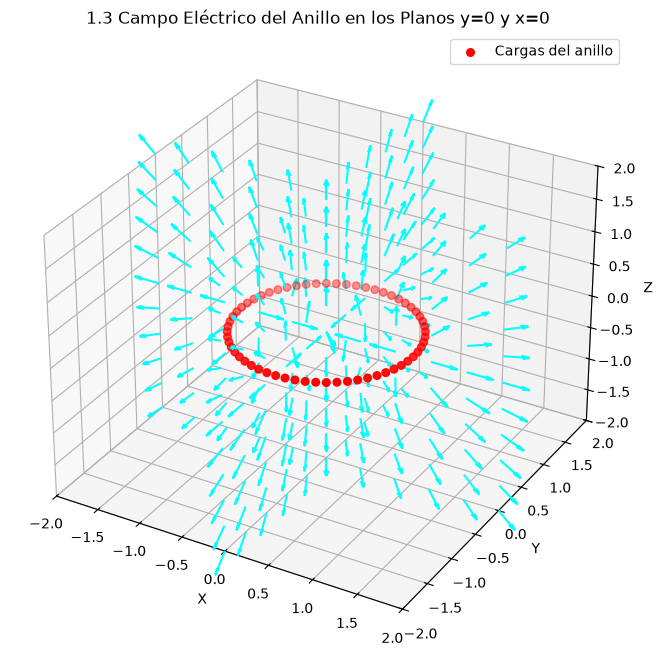

In [8]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Dibujar las N cargas del anillo en el plano xy
r_j_coords = posiciones_anillo(N_default)
ax.scatter(r_j_coords[:, 0], r_j_coords[:, 1], r_j_coords[:, 2], color='red', s=30, label='Cargas del anillo')

# Grilla de puntos
grid_coords = np.arange(-2.0, 2.1, 0.4)

def graficar_vectores_plano(plano='y0'):
    for a in grid_coords:
        for z in grid_coords:
            if plano == 'y0':
                x, y = a, 0.0
            else:
                x, y = 0.0, a
                if a == 0: continue # Evitar duplicar el centro

            r_pt = np.array([x, y, z])
            
            # Omitir si está a menos de 0.15 de alguna carga
            if np.min(np.linalg.norm(r_pt - r_j_coords, axis=1)) >= 0.15:
                E_v = campo_electrico(r_pt)
                E_arr = np.array([E_v.x, E_v.y, E_v.z])
                E_mag = np.linalg.norm(E_arr)
                
                if E_mag > 0:
                    # Flechas con longitud fija 0.3
                    dir_E = 0.3 * (E_arr / E_mag)
                    ax.quiver(x, y, z, dir_E[0], dir_E[1], dir_E[2], color='cyan', arrow_length_ratio=0.3)

# Graficar en ambos planos
graficar_vectores_plano('y0')
graficar_vectores_plano('x0')

ax.set_title("1.3 Campo Eléctrico del Anillo en los Planos y=0 y x=0")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_xlim([-2, 2])
ax.set_ylim([-2, 2])
ax.set_zlim([-2, 2])
plt.legend()
plt.show()




=== EJECUTANDO SIMULACIONES DE LA SECCIÓN 2 (MODO RÁPIDO) ===

--- Punto 2.1: r0 = (0, 0, 0.2), dt = 1e-3 ---
  -> Período medido: T_medido ≈ 12.8480 s


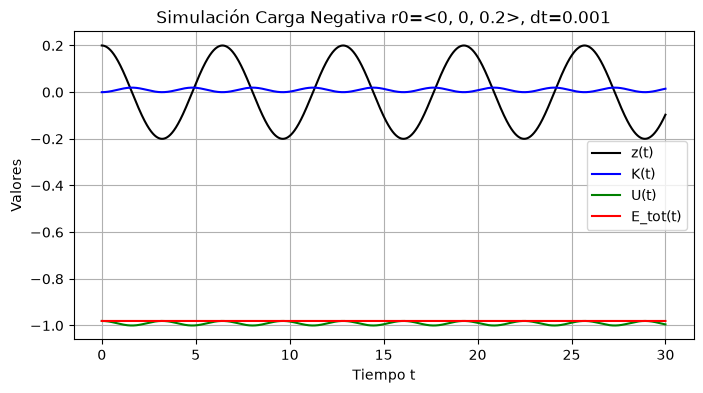


--- Punto 2.2: r0 = (0, 0, 1.5), dt = 1e-3 ---
  -> Período medido: T_medido ≈ 25.6140 s


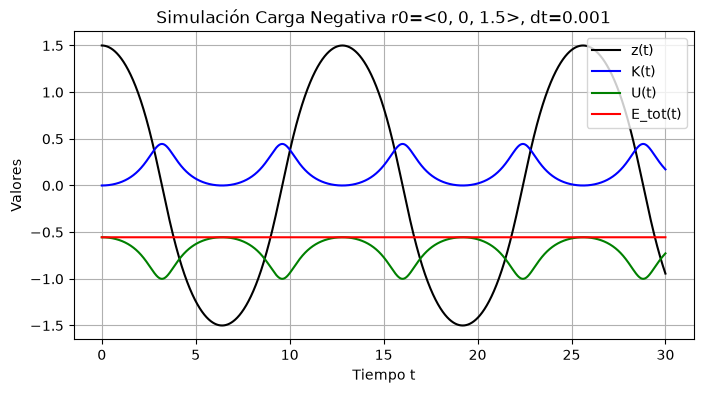


--- Punto 2.3: r0 = (0, 0, 1.5), dt = 1e-2 ---
  -> Período medido: T_medido ≈ 25.6200 s


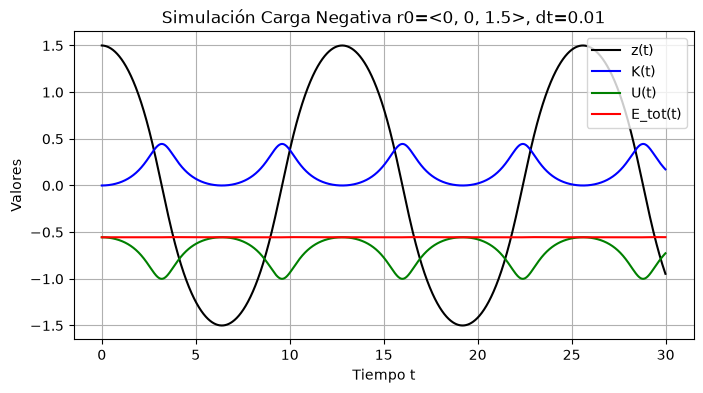


--- Punto 2.4: Perturbación fuera del eje r0 = (0.01, 0, 0.2) ---
  -> Simulación detenida en t=7.579 s por cercanía (<0.05) a una carga.
  -> Período medido: T_medido ≈ 11.7500 s


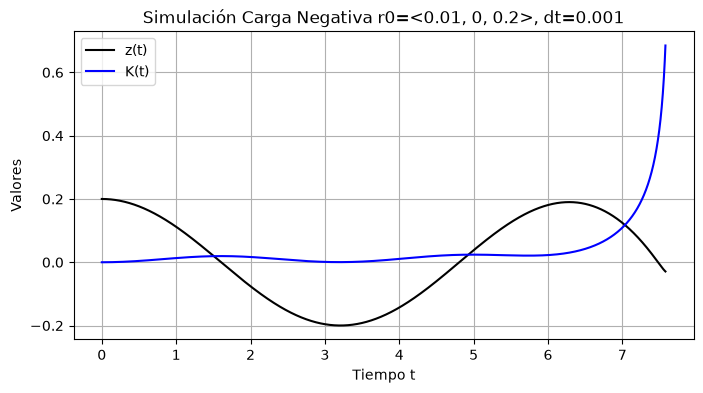

In [9]:
import matplotlib.pyplot as plt

def simular_oscilacion_rapida(r0, q=-1.0, dt=1e-3, t_max=30.0, detener_por_cercania=False):
    """
    Integra el movimiento usando el método de Euler sin bloquear VPython.
    Genera las gráficas de z(t) y energías de forma inmediata con Matplotlib.
    """
    r_j_coords = posiciones_anillo(N_default)
    
    # Vectores de estado iniciales
    pos = np.array([r0.x, r0.y, r0.z], dtype=float)
    v = np.array([0.0, 0.0, 0.0], dtype=float)
    
    # Arreglos para guardar la historia
    tiempos = []
    z_vals = []
    K_vals = []
    U_vals = []
    Etot_vals = []
    
    t = 0.0
    z_prev = pos[2]
    cruces_z = []
    
    N_pasos = int(t_max / dt)
    
    for _ in range(N_pasos):
        # 1. Campo eléctrico numérico
        E_v = campo_electrico(pos)
        E_arr = np.array([E_v.x, E_v.y, E_v.z])
        
        # 2. Fuerza y método de Euler
        F_v = q * E_arr
        v = v + (F_v / m) * dt
        pos = pos + v * dt
        
        # 3. Energías
        K = 0.5 * m * np.dot(v, v)
        
        # Si está sobre el eje x=0, y=0
        if abs(pos[0]) < 1e-5 and abs(pos[1]) < 1e-5:
            U = q * V_analitico(pos[2])
            Etot = K + U
        else:
            U = np.nan
            Etot = np.nan
            
        tiempos.append(t)
        z_vals.append(pos[2])
        K_vals.append(K)
        U_vals.append(U)
        Etot_vals.append(Etot)
        
        # Detección de cruce de positivo a negativo en z
        if z_prev > 0 and pos[2] <= 0:
            cruces_z.append(t)
        z_prev = pos[2]
        
        # Condición de parada por cercanía a cargas del anillo
        if detener_por_cercania:
            dist_min = np.min(np.linalg.norm(pos - r_j_coords, axis=1))
            if dist_min < 0.05:
                print(f"  -> Simulación detenida en t={t:.3f} s por cercanía (<0.05) a una carga.")
                break
                
        t += dt

    # Reporte de período
    if len(cruces_z) >= 2:
        periodo_medido = 2 * (cruces_z[1] - cruces_z[0])
        print(f"  -> Período medido: T_medido ≈ {periodo_medido:.4f} s")
    
    # Graficar resultados de la simulación
    plt.figure(figsize=(8, 4))
    plt.plot(tiempos, z_vals, 'k-', label='z(t)')
    plt.plot(tiempos, K_vals, 'b-', label='K(t)')
    if not np.isnan(U_vals[0]):
        plt.plot(tiempos, U_vals, 'g-', label='U(t)')
        plt.plot(tiempos, Etot_vals, 'r-', label='E_tot(t)')
    plt.title(f"Simulación Carga Negativa r0={r0}, dt={dt}")
    plt.xlabel("Tiempo t")
    plt.ylabel("Valores")
    plt.grid(True)
    plt.legend()
    plt.show()

print("\n=== EJECUTANDO SIMULACIONES DE LA SECCIÓN 2 (MODO RÁPIDO) ===")

# 2.1 Libere la partícula desde r0 = (0, 0, 0.2), t_max = 30
print("\n--- Punto 2.1: r0 = (0, 0, 0.2), dt = 1e-3 ---")
simular_oscilacion_rapida(vector(0, 0, 0.2), q=-1.0, dt=1e-3, t_max=30.0)

# 2.2 Repita con r0 = (0, 0, 1.5)
print("\n--- Punto 2.2: r0 = (0, 0, 1.5), dt = 1e-3 ---")
simular_oscilacion_rapida(vector(0, 0, 1.5), q=-1.0, dt=1e-3, t_max=30.0)

# 2.3 Repita r0 = (0, 0, 1.5) con dt = 1e-2
print("\n--- Punto 2.3: r0 = (0, 0, 1.5), dt = 1e-2 ---")
simular_oscilacion_rapida(vector(0, 0, 1.5), q=-1.0, dt=1e-2, t_max=30.0)

# 2.4 Perturbación r0 = (0.01, 0, 0.2) con t_max = 10
print("\n--- Punto 2.4: Perturbación fuera del eje r0 = (0.01, 0, 0.2) ---")
simular_oscilacion_rapida(vector(0.01, 0, 0.2), q=-1.0, dt=1e-3, t_max=10.0, detener_por_cercania=True)



In [ ]:
print("\n=== EJECUTANDO SIMULACIONES DE LA SECCIÓN 2 ===")

# 2.1 Libere la partícula desde r0 = (0, 0, 0.2), t_max = 30
print("\n--- Punto 2.1: r0 = (0, 0, 0.2), dt = 1e-3 ---")
E_tot_final_1 = simular_oscilacion(vector(0, 0, 0.2), q=-1.0, dt=1e-3, t_max=30.0)


=== EJECUTANDO SIMULACIONES DE LA SECCIÓN 2 ===

--- Punto 2.1: r0 = (0, 0, 0.2), dt = 1e-3 ---


<IPython.core.display.Javascript object>


--- Punto 2.2: r0 = (0, 0, 1.5), dt = 1e-3 ---
  -> Período medido: T_medido ≈ 25.6140 s


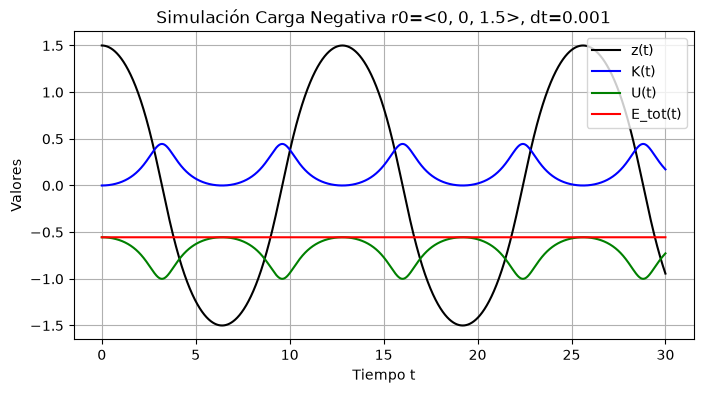

In [12]:
# 2.2 Repita con r0 = (0, 0, 1.5)
print("\n--- Punto 2.2: r0 = (0, 0, 1.5), dt = 1e-3 ---")
E_tot_final_2 = simular_oscilacion_rapida(vector(0, 0, 1.5), q=-1.0, dt=1e-3, t_max=30.0)


--- Punto 2.3: r0 = (0, 0, 1.5), dt = 1e-2 (Comparación de Energía) ---
  -> Período medido: T_medido ≈ 25.6200 s


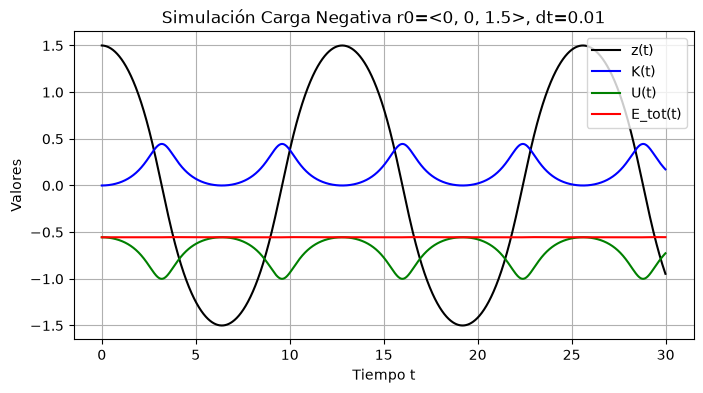

In [13]:
# 2.3 Repita r0 = (0, 0, 1.5) con dt = 1e-2 y comparar energías
print("\n--- Punto 2.3: r0 = (0, 0, 1.5), dt = 1e-2 (Comparación de Energía) ---")
E_tot_final_3 = simular_oscilacion_rapida(vector(0, 0, 1.5), q=-1.0, dt=1e-2, t_max=30.0)

In [14]:
# 2.4 Perturbación r0 = (0.01, 0, 0.2) con t_max = 10 y detección de cercanía
print("\n--- Punto 2.4: Perturbación fuera del eje r0 = (0.01, 0, 0.2) ---")


--- Punto 2.4: Perturbación fuera del eje r0 = (0.01, 0, 0.2) ---
